In [1]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import plotly.express as px
from IPython.display import display

print("Plotly imported successfully!")

Plotly imported successfully!


In [4]:
import pandas as pd
import getpass
from sqlalchemy import create_engine, URL

# Enter your MySQL password securely
mysql_password = getpass.getpass("Enter MySQL password: ")

# Create MySQL connection
connection_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=mysql_password,
    host="localhost",
    port=3306,
    database="cybersecurity_clean"
)

engine = create_engine(connection_url)

# Load the Security Engineer dataset
query = "SELECT * FROM security_engineer_final_v2"
df = pd.read_sql(query, engine)

# Verify that the dataset loaded
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Enter MySQL password:  ········


Dataset loaded successfully!
Dataset shape: (1559, 11)
Columns: ['technique_id', 'technique_name', 'technique_description', 'tactics', 'platforms', 'addressed_source_id', 'addressed_target_id', 'addressed_mapping_type', 'mitigation_id', 'mitigation_name', 'mitigation_description']


,technique_id,technique_name,technique_description,tactics,platforms,addressed_source_id,addressed_target_id,addressed_mapping_type,mitigation_id,mitigation_name,mitigation_description
0,T1001,Data Obfuscation,Adversaries may obfuscate command and control ...,Command and Control,"ESXi, Linux, Windows, macOS",M1031,T1001,mitigates,M1031,Network Intrusion Prevention,Use intrusion detection signatures to block tr...
1,T1001.001,Data Obfuscation: Junk Data,Adversaries may add junk data to protocols use...,Command and Control,"ESXi, Linux, Windows, macOS",M1031,T1001.001,mitigates,M1031,Network Intrusion Prevention,Use intrusion detection signatures to block tr...
2,T1001.002,Data Obfuscation: Steganography,Adversaries may use steganographic techniques ...,Command and Control,"ESXi, Linux, Windows, macOS",M1031,T1001.002,mitigates,M1031,Network Intrusion Prevention,Use intrusion detection signatures to block tr...
3,T1001.003,Data Obfuscation: Protocol or Service Imperson...,Adversaries may impersonate legitimate protoco...,Command and Control,"ESXi, Linux, Windows, macOS",M1031,T1001.003,mitigates,M1031,Network Intrusion Prevention,Use intrusion detection signatures to block tr...
4,T1003,OS Credential Dumping,Adversaries may attempt to dump credentials to...,Credential Access,"Linux, Windows, macOS",M1015,T1003,mitigates,M1015,Active Directory Configuration,Implement robust Active Directory (AD) configu...


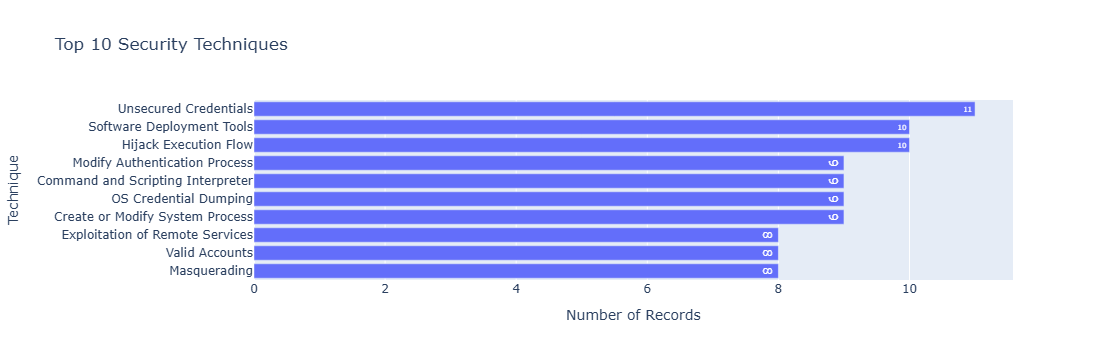

In [5]:
top_10_techniques = (
    df["technique_name"]
    .value_counts()
    .head(10)
    .rename_axis("technique_name")
    .reset_index(name="record_count")
)

fig = px.bar(
    top_10_techniques,
    x="record_count",
    y="technique_name",
    orientation="h",
    title="Top 10 Security Techniques",
    text="record_count",
    labels={
        "record_count": "Number of Records",
        "technique_name": "Technique"
    }
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

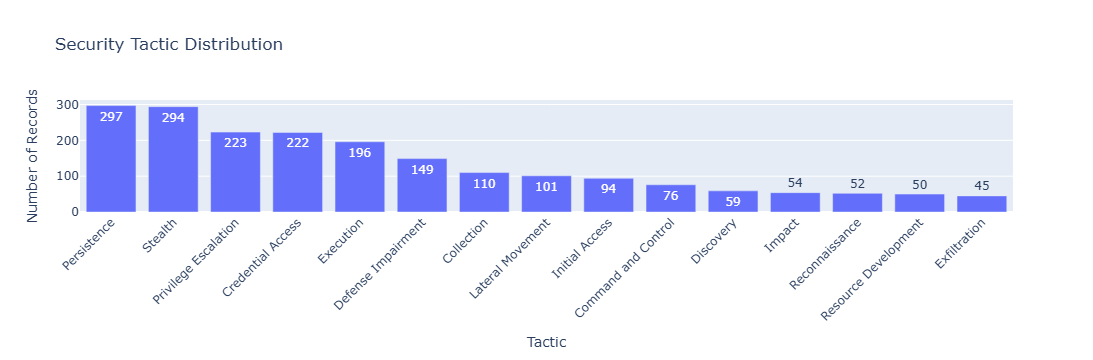

In [6]:
tactic_distribution = (
    df["tactics"]
    .dropna()
    .astype(str)
    .str.split(r",\s*")
    .explode()
    .str.strip()
)

tactic_distribution = (
    tactic_distribution[tactic_distribution.ne("")]
    .value_counts()
    .rename_axis("tactic_name")
    .reset_index(name="record_count")
)

fig = px.bar(
    tactic_distribution,
    x="tactic_name",
    y="record_count",
    title="Security Tactic Distribution",
    text="record_count",
    labels={
        "tactic_name": "Tactic",
        "record_count": "Number of Records"
    }
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

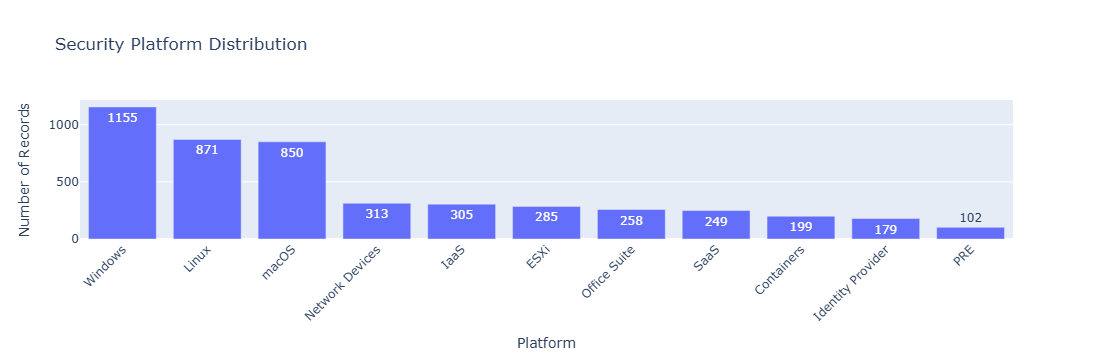

In [7]:
platform_distribution = (
    df["platforms"]
    .dropna()
    .astype(str)
    .str.split(r",\s*")
    .explode()
    .str.strip()
)

platform_distribution = (
    platform_distribution[
        platform_distribution.ne("") &
        platform_distribution.ne("nan")
    ]
    .value_counts()
    .rename_axis("platform_name")
    .reset_index(name="record_count")
)

fig = px.bar(
    platform_distribution,
    x="platform_name",
    y="record_count",
    title="Security Platform Distribution",
    text="record_count",
    labels={
        "platform_name": "Platform",
        "record_count": "Number of Records"
    }
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

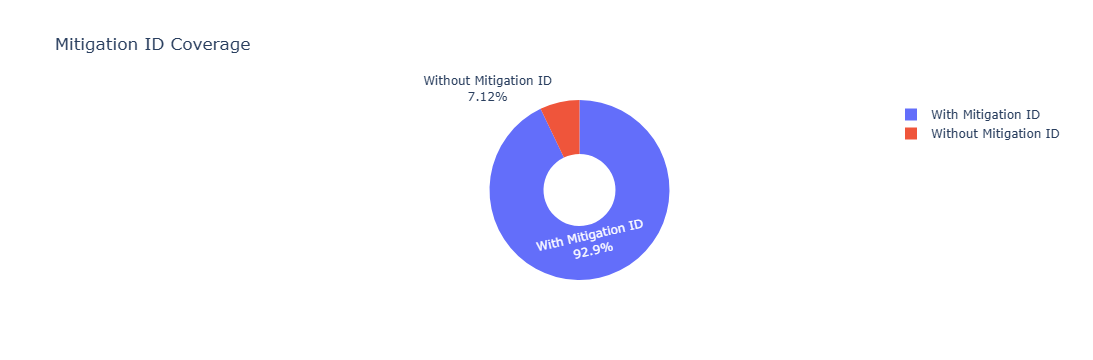

In [8]:
mitigation_summary = pd.DataFrame({
    "Status": [
        "With Mitigation ID",
        "Without Mitigation ID"
    ],
    "Count": [
        df["mitigation_id"].notna().sum(),
        df["mitigation_id"].isna().sum()
    ]
})

fig = px.pie(
    mitigation_summary,
    names="Status",
    values="Count",
    title="Mitigation ID Coverage",
    hole=0.4
)

fig.update_traces(
    textinfo="label+percent",
    hovertemplate="%{label}<br>Records: %{value}<br>Percentage: %{percent}<extra></extra>"
)

fig.show()

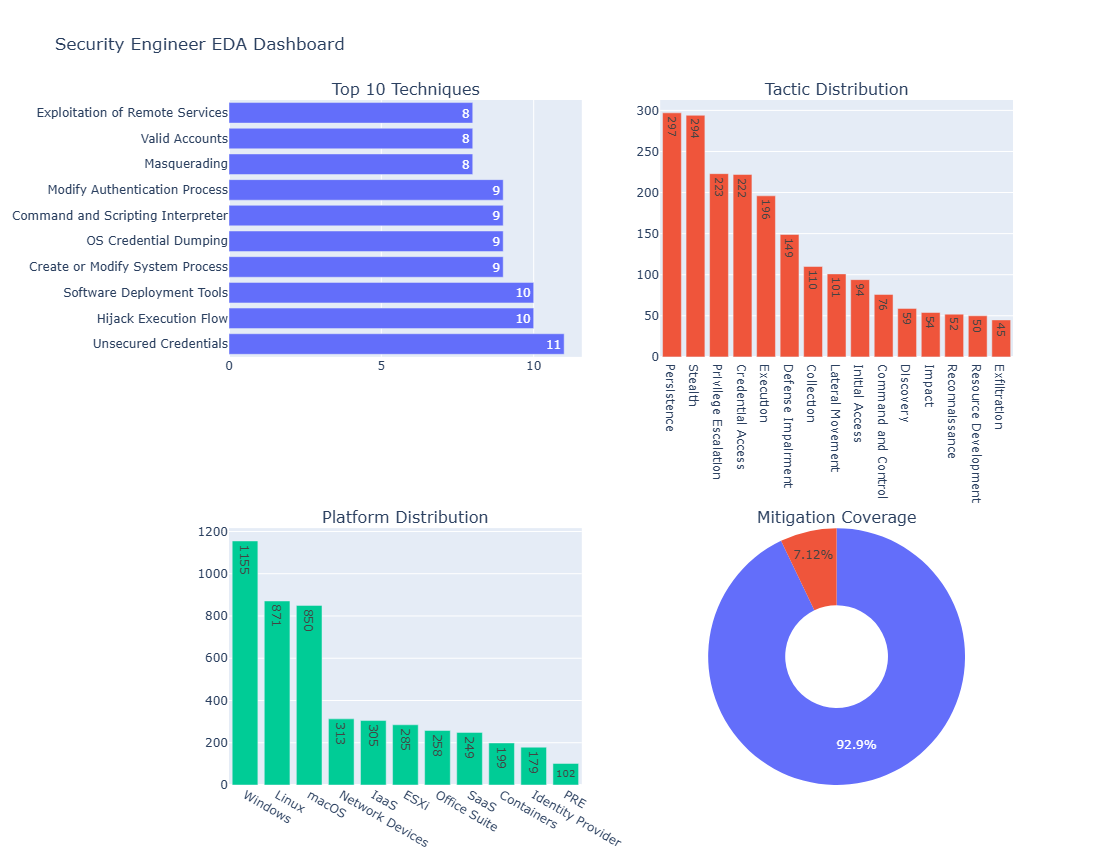

In [9]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Top 10 Techniques",
        "Tactic Distribution",
        "Platform Distribution",
        "Mitigation Coverage"
    ),
    specs=[
        [{"type": "bar"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "pie"}]
    ]
)

# Chart 1: Top 10 techniques
fig.add_trace(
    go.Bar(
        x=top_10_techniques["record_count"],
        y=top_10_techniques["technique_name"],
        orientation="h",
        text=top_10_techniques["record_count"],
        textposition="auto",
        name="Techniques"
    ),
    row=1, col=1
)

# Chart 2: Tactic distribution
fig.add_trace(
    go.Bar(
        x=tactic_distribution["tactic_name"],
        y=tactic_distribution["record_count"],
        text=tactic_distribution["record_count"],
        textposition="auto",
        name="Tactics"
    ),
    row=1, col=2
)

# Chart 3: Platform distribution
fig.add_trace(
    go.Bar(
        x=platform_distribution["platform_name"],
        y=platform_distribution["record_count"],
        text=platform_distribution["record_count"],
        textposition="auto",
        name="Platforms"
    ),
    row=2, col=1
)

# Chart 4: Mitigation coverage
fig.add_trace(
    go.Pie(
        labels=mitigation_summary["Status"],
        values=mitigation_summary["Count"],
        hole=0.4
    ),
    row=2, col=2
)

fig.update_layout(
    title_text="Security Engineer EDA Dashboard",
    height=850,
    width=1400,
    showlegend=False
)

fig.show()

In [10]:
fig.write_html("security_engineer_plotly_dashboard.html")

print("Plotly dashboard saved successfully!")

Plotly dashboard saved successfully!
